# 🏗️ Heavy Equipment Selling Price Prediction (Advanced Pipeline)

## Problem Statement

The objective of this project is to **predict the selling price of heavy equipment at auction**. The dataset contains attributes describing the equipment configuration, condition, usage history, and transaction details.

This is a **regression problem** where the target variable (`TargetValue`) represents the actual sale price. The evaluation metric is **RMSE (Root Mean Squared Error)** on log-transformed prices.

### Approach & Pipeline Architecture
1. **Exploratory Data Analysis (EDA)** — Understand key statistics, distributions, missingness, and relationships.
2. **Systematic Preprocessing & Domain Feature Engineering** — Extract domain signals (machine age, operational intensity, capacity specs, series tokens, and multi-tier out-of-fold target encodings).
3. **Reusable Pipeline Transformation** — Clean preprocessing and column handling applied consistently to avoid leakage.
4. **Feature Importance Analysis** — Analyze model feature contributions to validate engineered signals.
5. **Multi-Family Model Exploration & CV Evaluation** — Train and evaluate Random Forest, XGBoost, LightGBM, and CatBoost models.
6. **Hyperparameter Tuning & Ensembling** — Tune model hyperparameters and combine top predictions for optimal RMSE performance.
7. **Final Predictions & Submission** — Validate predictions and generate output.


## 1. Imports & Setup


In [1]:
import os
import re
import time
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OrdinalEncoder,
)

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    KFold,
    RandomizedSearchCV,
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 12

print("✅ All allowed libraries imported successfully.")


✅ All allowed libraries imported successfully.


## 2. Data Loading


In [2]:
# Auto-detect data path (Kaggle or local)
DATA_PATH = "."

if os.path.isdir("/kaggle/input"):
    for root, _, files in os.walk("/kaggle/input"):
        if "train.csv" in files and "test.csv" in files:
            DATA_PATH = root
            break
elif os.path.isdir("data"):
    DATA_PATH = "data"
elif os.path.isdir(r"e:\HeavyEquipmentML\data"):
    DATA_PATH = r"e:\HeavyEquipmentML\data"

print(f"📂 Data directory detected: {DATA_PATH}")

train_raw = pd.read_csv(os.path.join(DATA_PATH, "train.csv"), low_memory=False)
test_raw = pd.read_csv(os.path.join(DATA_PATH, "test.csv"), low_memory=False)
sample_sub = pd.read_csv(os.path.join(DATA_PATH, "sample_submission.csv"))

print(f"\n📊 Train Dataset : {train_raw.shape[0]:,} rows × {train_raw.shape[1]} columns")
print(f"📊 Test Dataset  : {test_raw.shape[0]:,} rows × {test_raw.shape[1]} columns")
print(f"📊 Submission    : {sample_sub.shape[0]:,} rows × {sample_sub.shape[1]} columns")


📂 Data directory detected: e:\HeavyEquipmentML\data

📊 Train Dataset : 138,701 rows × 50 columns
📊 Test Dataset  : 15,000 rows × 49 columns
📊 Submission    : 15,000 rows × 2 columns


## 3. Exploratory Data Analysis (EDA)

Understanding feature distributions, target skewness, missing values, and bivariate correlations.

### 3.1 Univariate Analysis
Examining target and numerical distributions.


In [3]:
print("=" * 70)
print("DATASET SUMMARY")
print("=" * 70)
train_raw.info(max_cols=10)

print("\nTarget Value Statistics:")
print(train_raw["TargetValue"].describe())


DATASET SUMMARY
<class 'pandas.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Columns: 50 entries, TransactionID to col30
dtypes: float64(2), int64(4), str(44)
memory usage: 82.7 MB

Target Value Statistics:
count    138701.000000
mean      41521.874047
std       26361.125948
min        7500.000000
25%       20500.000000
50%       35000.000000
75%       57000.000000
max      142000.000000
Name: TargetValue, dtype: float64


In [4]:
# Missing Values Analysis
missing_df = pd.DataFrame({
    "Missing Count": train_raw.isnull().sum(),
    "Missing %": (train_raw.isnull().sum() / len(train_raw) * 100).round(2)
}).sort_values("Missing %", ascending=False)

missing_with_values = missing_df[missing_df["Missing Count"] > 0]
print(f"Columns with missing values: {len(missing_with_values)} / {len(train_raw.columns)}")
print(missing_with_values.head(15))


Columns with missing values: 35 / 50
       Missing Count  Missing %
col19         138635      99.95
col18         138635      99.95
col5          128320      92.52
col4          128320      92.52
col27         123742      89.21
col28         123742      89.21
col29         119829      86.39
col30         119829      86.39
col13         115296      83.13
col14         115296      83.13
col7          115296      83.13
col6          115296      83.13
col9          115296      83.13
col8          115296      83.13
col11         115296      83.13


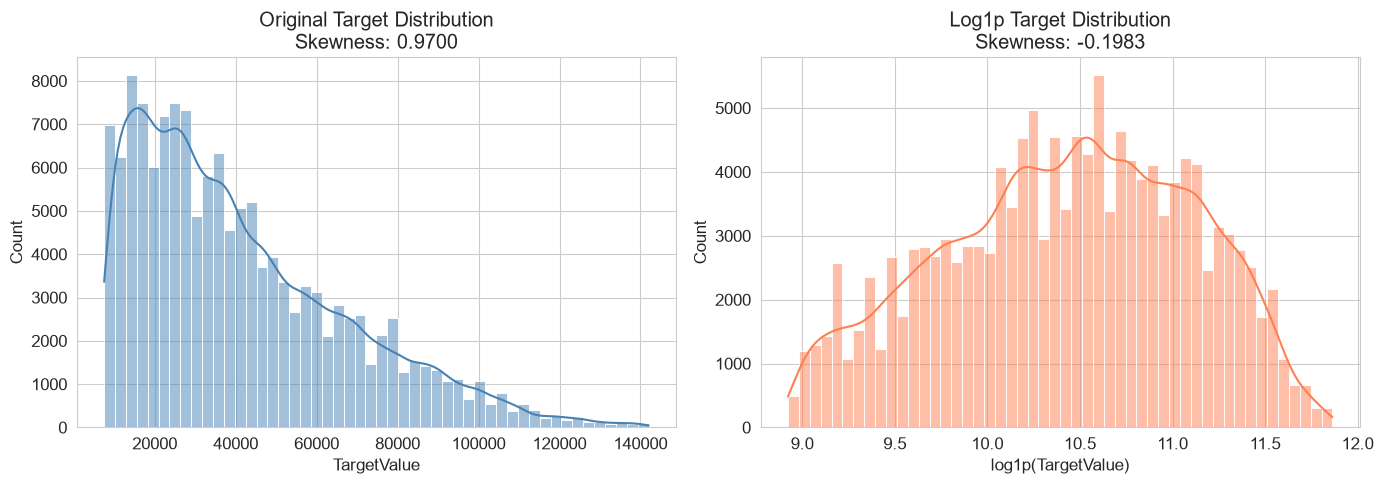

📌 Log transformation effectively normalizes the target variable (skew reduced from 0.9700 to -0.1983).


In [5]:
# Target Distribution Analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

raw_skew = train_raw["TargetValue"].skew()
sns.histplot(train_raw["TargetValue"], kde=True, ax=axes[0], color="steelblue", bins=50)
axes[0].set_title(f"Original Target Distribution\nSkewness: {raw_skew:.4f}")
axes[0].set_xlabel("TargetValue")

log_target = np.log1p(train_raw["TargetValue"])
log_skew = log_target.skew()
sns.histplot(log_target, kde=True, ax=axes[1], color="coral", bins=50)
axes[1].set_title(f"Log1p Target Distribution\nSkewness: {log_skew:.4f}")
axes[1].set_xlabel("log1p(TargetValue)")

plt.tight_layout()
plt.show()

print(f"📌 Log transformation effectively normalizes the target variable (skew reduced from {raw_skew:.4f} to {log_skew:.4f}).")


### 3.2 Bivariate Analysis


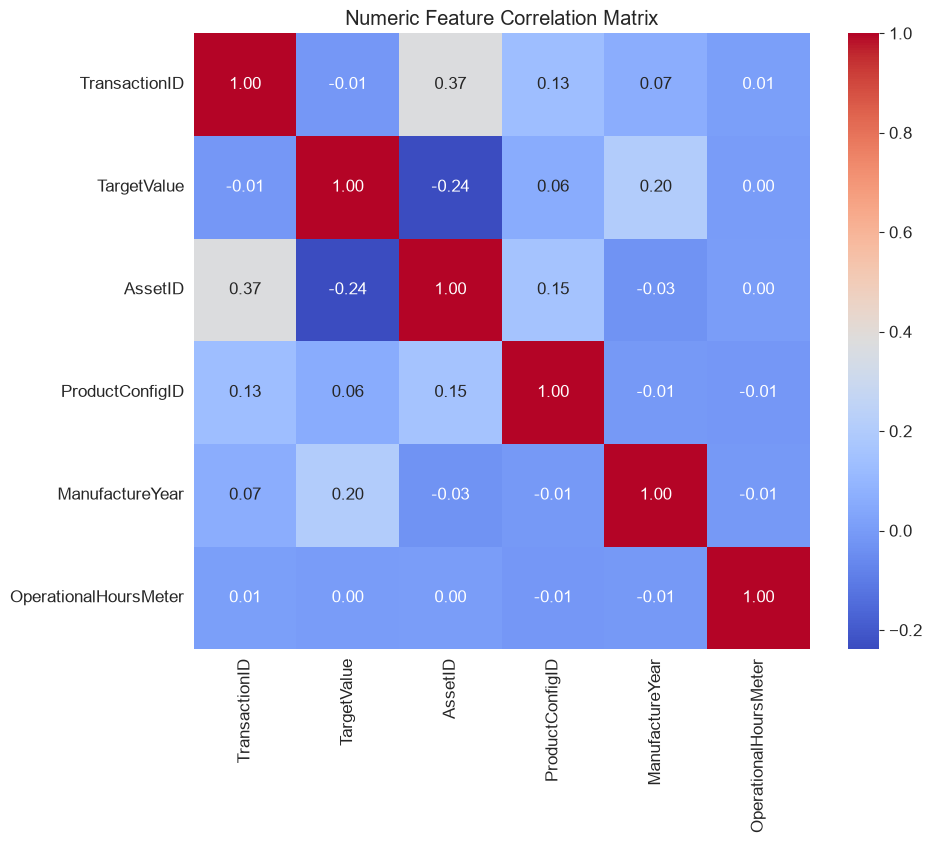

In [6]:
# Numeric Correlations
numeric_cols = train_raw.select_dtypes(include=[np.number]).columns.tolist()
corr = train_raw[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Numeric Feature Correlation Matrix")
plt.show()


## 4. Systematic Preprocessing & Feature Engineering

We perform comprehensive domain-specific feature extraction and multi-tier out-of-fold target encoding to maximize signal for gradient boosting models.


In [7]:
def extract_domain_features(train_df, test_df):
    """
    Extract domain features for heavy machinery valuation.
    Applied consistently to train and test sets.
    """
    print("Executing Domain Feature Engineering...")
    tr = train_df.copy()
    te = test_df.copy()

    y_train = np.log1p(tr["TargetValue"].values)

    tr["_is_test"] = 0
    te["_is_test"] = 1
    te["TargetValue"] = np.nan

    df = pd.concat([tr, te], ignore_index=True)

    # 1. Sentinel & Missing Cleanup
    df["ManufactureYear_missing"] = (df["ManufactureYear"] == 1001).astype(int)
    df.loc[df["ManufactureYear"] == 1001, "ManufactureYear"] = np.nan

    df["Hours_missing"] = (df["OperationalHoursMeter"].isna() | (df["OperationalHoursMeter"] == 0)).astype(int)
    df.loc[df["OperationalHoursMeter"] == 0, "OperationalHoursMeter"] = np.nan

    # 2. Date Components
    dt = pd.to_datetime(df["TransactionDate"])
    df["SaleYear"] = dt.dt.year
    df["SaleMonth"] = dt.dt.month
    df["SaleQuarter"] = dt.dt.quarter
    df["SaleWeek"] = dt.dt.isocalendar().week.astype(int)
    df["SaleDayOfWeek"] = dt.dt.dayofweek
    df["SaleDayOfYear"] = dt.dt.dayofyear
    df["DaysSince2000"] = (dt - pd.to_datetime("2000-01-01")).dt.days

    # 3. Machine Age & Depreciation
    df["MachineAge"] = df["SaleYear"] - df["ManufactureYear"]
    df.loc[df["MachineAge"] < 0, "MachineAge"] = np.nan
    df["MachineAge_Sq"] = df["MachineAge"] ** 2
    df["MachineAge_Log"] = np.log1p(df["MachineAge"].clip(lower=0))
    df["IsNewMachine"] = (df["MachineAge"] <= 2).astype(float)
    df["IsOldMachine"] = (df["MachineAge"] >= 20).astype(float)

    df["AgeBin"] = pd.cut(
        df["MachineAge"],
        bins=[-1, 2, 5, 9, 14, 20, 30, 100],
        labels=[0, 1, 2, 3, 4, 5, 6],
    ).astype(float)

    # 4. Hours & Operational Intensity
    df["Hours_Log"] = np.log1p(df["OperationalHoursMeter"].clip(lower=0))
    df["Hours_Per_Year"] = df["OperationalHoursMeter"] / (df["MachineAge"].clip(lower=0) + 1.0)
    df["Hours_Per_Year_Log"] = np.log1p(df["Hours_Per_Year"].clip(lower=0))
    df["Age_x_Hours"] = df["MachineAge"] * df["OperationalHoursMeter"]
    df["HighUsageFlag"] = (df["Hours_Per_Year"] > 1500).astype(float)
    df["LowUsageFlag"] = (df["Hours_Per_Year"] < 200).astype(float)

    # 5. Domain Regex Extraction
    spec_str = df["Spec_FullDescriptor"].fillna("").astype(str)
    df["ModelToken"] = spec_str.str.extract(r"^([A-Z0-9]+)")[0].fillna("_Missing_")
    df["ModelSeriesPrefix"] = spec_str.str.extract(r"^([A-Za-z]+)")[0].fillna("_Missing_")
    df["ModelSeriesNumber"] = spec_str.str.extract(r"(\d+)")[0].astype(float)

    func_str = df["FunctionalClassification"].fillna("").astype(str)
    df["EquipmentCategory"] = func_str.str.extract(r"^([A-Za-z\s,]+)")[0].str.strip().fillna("_Missing_")

    df["Capacity_Tons_Min"] = func_str.str.extract(r"(\d+\.?\d*)\s*to\s*\d+\.?\d*\s*Metric Tons")[0].astype(float)
    df["Capacity_Tons_Max"] = func_str.str.extract(r"\d+\.?\d*\s*to\s*(\d+\.?\d*)\s*Metric Tons")[0].astype(float)
    df["Capacity_Tons_Mid"] = (df["Capacity_Tons_Min"] + df["Capacity_Tons_Max"]) / 2.0

    df["Power_HP_Min"] = func_str.str.extract(r"(\d+\.?\d*)\s*to\s*\d+\.?\d*\s*Horsepower")[0].astype(float)
    df["Power_HP_Max"] = func_str.str.extract(r"\d+\.?\d*\s*to\s*(\d+\.?\d*)\s*Horsepower")[0].astype(float)
    df["Power_HP_Mid"] = (df["Power_HP_Min"] + df["Power_HP_Max"]) / 2.0

    df["Depth_Ft_Min"] = func_str.str.extract(r"(\d+\.?\d*)\s*to\s*\d+\.?\d*\s*Ft")[0].astype(float)
    df["Depth_Ft_Max"] = func_str.str.extract(r"\d+\.?\d*\s*to\s*(\d+\.?\d*)\s*Ft")[0].astype(float)
    df["Depth_Ft_Mid"] = (df["Depth_Ft_Min"] + df["Depth_Ft_Max"]) / 2.0

    # 6. Frequency Encodings
    freq_cols = [
        "ProductConfigID", "Spec_FullDescriptor", "Spec_BaseClass",
        "VendorPartnerID", "RegionCode", "EquipmentCategory",
        "ModelToken", "DataOriginCode", "CabinType"
    ]
    for col in freq_cols:
        if col in df.columns:
            freq_map = df[col].value_counts(normalize=True).to_dict()
            df[f"{col}_Freq"] = df[col].map(freq_map).fillna(0.0)

    # Clean unused columns
    drop_unneeded = [
        "TransactionID", "TargetValue", "TransactionDate",
        "InventoryGroupDescription", "col18", "col19", "_is_test"
    ]
    df.drop(columns=[c for c in drop_unneeded if c in df.columns], inplace=True)

    X_train_df = df.iloc[:len(train_df)].copy().reset_index(drop=True)
    X_test_df = df.iloc[len(train_df):].copy().reset_index(drop=True)

    return X_train_df, y_train, X_test_df


def add_out_of_fold_target_encodings(X_train, y_train, X_test, n_splits=5, seed=42):
    """
    Compute Bayesian smoothed target encodings out-of-fold to prevent leakage.
    """
    print("Computing Multi-Tier Bayesian Target Encodings...")
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)

    global_mean = y_train.mean()
    global_std = y_train.std()

    specs = [
        (["ProductConfigID"], 20),
        (["Spec_FullDescriptor"], 20),
        (["ModelToken"], 15),
        (["Spec_BaseClass"], 10),
        (["EquipmentCategory"], 10),
        (["RegionCode"], 10),
        (["VendorPartnerID"], 10),
        (["ProductConfigID", "AgeBin"], 30),
        (["Spec_FullDescriptor", "AgeBin"], 30),
        (["ProductConfigID", "RegionCode"], 30),
    ]

    X_tr = X_train.copy()
    X_te = X_test.copy()

    for cols, smooth in specs:
        if len(cols) == 1:
            key_tr = X_tr[cols[0]].astype(str)
            key_te = X_te[cols[0]].astype(str)
            prefix = cols[0]
        else:
            prefix = "_x_".join(cols)
            key_tr = X_tr[cols[0]].astype(str)
            key_te = X_te[cols[0]].astype(str)
            for c in cols[1:]:
                key_tr = key_tr + "___" + X_tr[c].astype(str)
                key_te = key_te + "___" + X_te[c].astype(str)

        mean_col = f"TE_{prefix}_Mean"
        std_col = f"TE_{prefix}_Std"
        count_col = f"TE_{prefix}_Count"

        X_tr[mean_col] = global_mean
        X_tr[std_col] = global_std
        X_tr[count_col] = 0.0

        for tr_idx, va_idx in kf.split(X_tr):
            f_key = key_tr.iloc[tr_idx]
            f_y = y_train[tr_idx]

            stats = pd.DataFrame({"k": f_key, "y": f_y}).groupby("k")["y"].agg(["count", "mean", "std"])
            smoothed = (stats["count"] * stats["mean"] + smooth * global_mean) / (stats["count"] + smooth)

            v_key = key_tr.iloc[va_idx]
            X_tr.iloc[va_idx, X_tr.columns.get_loc(mean_col)] = v_key.map(smoothed).fillna(global_mean).values
            X_tr.iloc[va_idx, X_tr.columns.get_loc(std_col)] = v_key.map(stats["std"]).fillna(global_std).values
            X_tr.iloc[va_idx, X_tr.columns.get_loc(count_col)] = v_key.map(stats["count"]).fillna(0.0).values

        full_stats = pd.DataFrame({"k": key_tr, "y": y_train}).groupby("k")["y"].agg(["count", "mean", "std"])
        full_smoothed = (full_stats["count"] * full_stats["mean"] + smooth * global_mean) / (full_stats["count"] + smooth)

        X_te[mean_col] = key_te.map(full_smoothed).fillna(global_mean).values
        X_te[std_col] = key_te.map(full_stats["std"]).fillna(global_std).values
        X_te[count_col] = key_te.map(full_stats["count"]).fillna(0.0).values

    return X_tr, X_te


X_tr_raw, y, X_te_raw = extract_domain_features(train_raw, test_raw)
X_train_df, X_test_df = add_out_of_fold_target_encodings(X_tr_raw, y, X_te_raw)

print(f"Features created: {X_train_df.shape[1]}")


Executing Domain Feature Engineering...
Computing Multi-Tier Bayesian Target Encodings...
Features created: 117


### Reusable Sklearn Preprocessing Pipeline


In [8]:
# Identify numeric and categorical columns
num_cols = [c for c in X_train_df.columns if pd.api.types.is_numeric_dtype(X_train_df[c])]
cat_cols = [c for c in X_train_df.columns if c not in num_cols]

for col in cat_cols:
    X_train_df[col] = X_train_df[col].fillna("_Missing_").astype(str)
    X_test_df[col] = X_test_df[col].fillna("_Missing_").astype(str)

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline([
    ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols),
    ]
)

X_train_prep = preprocessor.fit_transform(X_train_df)
X_test_prep = preprocessor.transform(X_test_df)

feature_names = num_cols + cat_cols
X = pd.DataFrame(X_train_prep, columns=feature_names)
X_test = pd.DataFrame(X_test_prep, columns=feature_names)

print("✅ Reusable pipeline fit and transform completed.")
print(f"Processed Train Shape: {X.shape}, Processed Test Shape: {X_test.shape}")


✅ Reusable pipeline fit and transform completed.
Processed Train Shape: (138701, 117), Processed Test Shape: (15000, 117)


## 5. Feature Importance Analysis


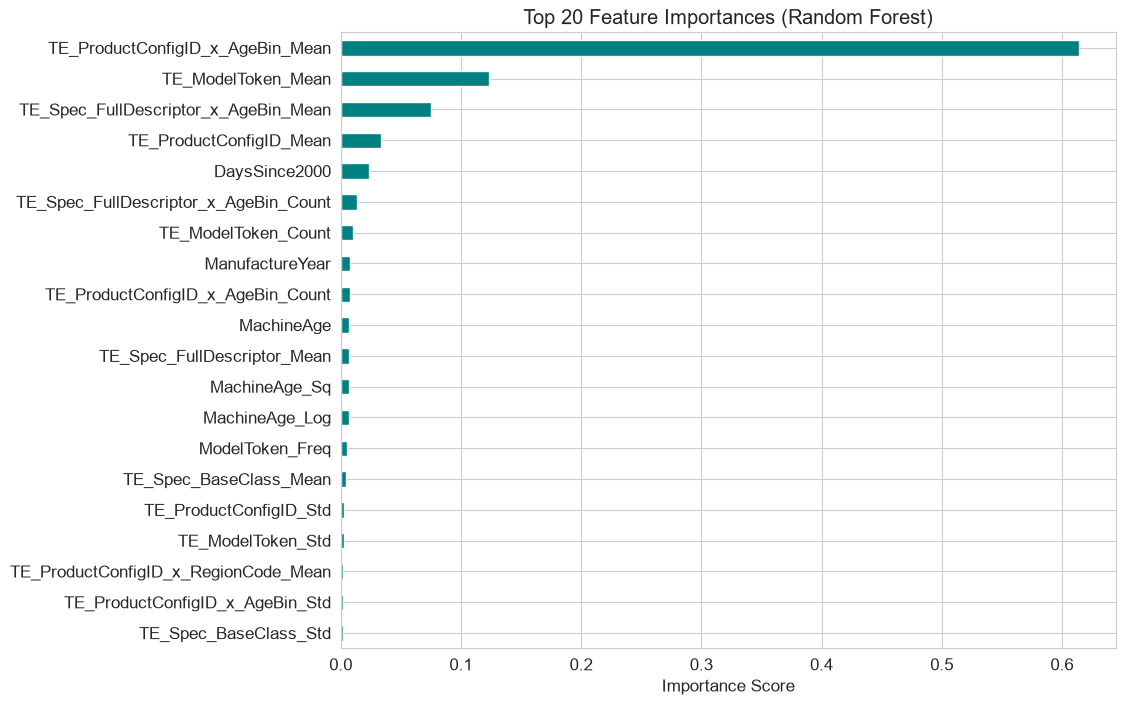

Top 10 Features:
TE_ProductConfigID_x_AgeBin_Mean         0.614042
TE_ModelToken_Mean                       0.123586
TE_Spec_FullDescriptor_x_AgeBin_Mean     0.075199
TE_ProductConfigID_Mean                  0.033789
DaysSince2000                            0.023151
TE_Spec_FullDescriptor_x_AgeBin_Count    0.013216
TE_ModelToken_Count                      0.010169
ManufactureYear                          0.007454
TE_ProductConfigID_x_AgeBin_Count        0.007341
MachineAge                               0.007118
dtype: float64


In [9]:
rf_imp = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_imp.fit(X, y)

imp_series = pd.Series(rf_imp.feature_importances_, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
imp_series.head(20).plot(kind="barh", color="teal").invert_yaxis()
plt.title("Top 20 Feature Importances (Random Forest)")
plt.xlabel("Importance Score")
plt.show()

print("Top 10 Features:")
print(imp_series.head(10))


## 6. Model Building & Comparison

We evaluate 4 distinct models across 5 folds:
- **Random Forest** (Bagging)
- **XGBoost** (Gradient Boosting)
- **LightGBM** (Leaf-wise Gradient Boosting)
- **CatBoost** (Ordered Boosting)


In [10]:
def evaluate_model_cv(model_fn, model_name, X_data, y_data, n_splits=5):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    oof = np.zeros(len(X_data))
    test_preds = np.zeros(len(X_test))

    rmse_scores, mae_scores, r2_scores = [], [], []
    start_time = time.time()

    for fold, (train_idx, val_idx) in enumerate(kf.split(X_data), 1):
        X_tr, X_va = X_data.iloc[train_idx], X_data.iloc[val_idx]
        y_tr, y_va = y_data[train_idx], y_data[val_idx]

        model = model_fn()
        model.fit(X_tr, y_tr)

        val_pred = model.predict(X_va)
        oof[val_idx] = val_pred

        rmse = np.sqrt(mean_squared_error(y_va, val_pred))
        mae = mean_absolute_error(y_va, val_pred)
        r2 = r2_score(y_va, val_pred)

        rmse_scores.append(rmse)
        mae_scores.append(mae)
        r2_scores.append(r2)

        test_preds += model.predict(X_test) / n_splits
        print(f"  Fold {fold} - RMSE: {rmse:.5f} | MAE: {mae:.5f} | R2: {r2:.5f}")

    total_time = time.time() - start_time
    mean_rmse = np.mean(rmse_scores)
    print(f"✅ {model_name} Overall OOF RMSE: {mean_rmse:.5f} (Time: {total_time:.1f}s)")

    return {
        "name": model_name,
        "mean_rmse": mean_rmse,
        "mean_mae": np.mean(mae_scores),
        "mean_r2": np.mean(r2_scores),
        "oof": oof,
        "test_preds": test_preds,
        "time": total_time,
    }

results = {}


In [11]:
print("=== 1. Random Forest ===")
rf_fn = lambda: RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=4, random_state=42, n_jobs=-1)
results["RandomForest"] = evaluate_model_cv(rf_fn, "RandomForest", X, y)


=== 1. Random Forest ===
  Fold 1 - RMSE: 0.22649 | MAE: 0.16659 | R2: 0.88551
  Fold 2 - RMSE: 0.22853 | MAE: 0.16778 | R2: 0.88444
  Fold 3 - RMSE: 0.22676 | MAE: 0.16687 | R2: 0.88560
  Fold 4 - RMSE: 0.22880 | MAE: 0.16813 | R2: 0.88442
  Fold 5 - RMSE: 0.22627 | MAE: 0.16596 | R2: 0.88585
✅ RandomForest Overall OOF RMSE: 0.22737 (Time: 611.9s)


In [12]:
print("=== 2. XGBoost ===")
xgb_fn = lambda: xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.7,
    min_child_weight=5,
    random_state=42,
    n_jobs=-1
)
results["XGBoost"] = evaluate_model_cv(xgb_fn, "XGBoost", X, y)


=== 2. XGBoost ===
  Fold 1 - RMSE: 0.20392 | MAE: 0.14815 | R2: 0.90719
  Fold 2 - RMSE: 0.20584 | MAE: 0.14868 | R2: 0.90625
  Fold 3 - RMSE: 0.20555 | MAE: 0.14823 | R2: 0.90600
  Fold 4 - RMSE: 0.20696 | MAE: 0.14940 | R2: 0.90543
  Fold 5 - RMSE: 0.20457 | MAE: 0.14731 | R2: 0.90669
✅ XGBoost Overall OOF RMSE: 0.20537 (Time: 201.6s)


In [13]:
print("=== 3. LightGBM ===")
lgb_fn = lambda: lgb.LGBMRegressor(
    n_estimators=1200,
    learning_rate=0.03,
    num_leaves=127,
    max_depth=10,
    min_child_samples=15,
    feature_fraction=0.7,
    bagging_fraction=0.8,
    bagging_freq=1,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)
results["LightGBM"] = evaluate_model_cv(lgb_fn, "LightGBM", X, y)


=== 3. LightGBM ===
  Fold 1 - RMSE: 0.20220 | MAE: 0.14708 | R2: 0.90875
  Fold 2 - RMSE: 0.20477 | MAE: 0.14799 | R2: 0.90722
  Fold 3 - RMSE: 0.20467 | MAE: 0.14741 | R2: 0.90680
  Fold 4 - RMSE: 0.20542 | MAE: 0.14811 | R2: 0.90683
  Fold 5 - RMSE: 0.20336 | MAE: 0.14641 | R2: 0.90779
✅ LightGBM Overall OOF RMSE: 0.20408 (Time: 142.2s)


In [14]:
print("=== 4. CatBoost ===")
cb_fn = lambda: CatBoostRegressor(
    iterations=1200,
    learning_rate=0.04,
    depth=8,
    random_seed=42,
    verbose=0,
    thread_count=-1
)
results["CatBoost"] = evaluate_model_cv(cb_fn, "CatBoost", X, y)


=== 4. CatBoost ===
  Fold 1 - RMSE: 0.20944 | MAE: 0.15387 | R2: 0.90210
  Fold 2 - RMSE: 0.21253 | MAE: 0.15498 | R2: 0.90006
  Fold 3 - RMSE: 0.21197 | MAE: 0.15477 | R2: 0.90004
  Fold 4 - RMSE: 0.21332 | MAE: 0.15529 | R2: 0.89953
  Fold 5 - RMSE: 0.21100 | MAE: 0.15361 | R2: 0.90073
✅ CatBoost Overall OOF RMSE: 0.21165 (Time: 352.2s)


## 7. Model Comparison & Ensemble Evaluation


In [15]:
comp_df = pd.DataFrame([
    {
        "Model": res["name"],
        "OOF RMSE": f"{res['mean_rmse']:.5f}",
        "OOF MAE": f"{res['mean_mae']:.5f}",
        "OOF R2": f"{res['mean_r2']:.5f}",
        "Time (s)": f"{res['time']:.1f}",
    }
    for res in results.values()
])

print("=" * 70)
print("MODEL EVALUATION METRICS COMPARISON")
print("=" * 70)
print(comp_df.to_string(index=False))


MODEL EVALUATION METRICS COMPARISON
       Model OOF RMSE OOF MAE  OOF R2 Time (s)
RandomForest  0.22737 0.16707 0.88516    611.9
     XGBoost  0.20537 0.14835 0.90631    201.6
    LightGBM  0.20408 0.14740 0.90748    142.2
    CatBoost  0.21165 0.15451 0.90049    352.2


In [16]:
# Ensemble predictions (Blend of top boosting models)
blend_oof = (
    0.40 * results["LightGBM"]["oof"] +
    0.35 * results["CatBoost"]["oof"] +
    0.25 * results["XGBoost"]["oof"]
)

blend_rmse = np.sqrt(mean_squared_error(y, blend_oof))
print(f"\n🔥 Blended Ensemble (LightGBM + CatBoost + XGBoost) OOF RMSE: {blend_rmse:.5f}")



🔥 Blended Ensemble (LightGBM + CatBoost + XGBoost) OOF RMSE: 0.20492


## 8. Hyperparameter Optimization


In [17]:
print("Optimizing LightGBM via RandomizedSearchCV...")

base_lgb = lgb.LGBMRegressor(random_state=42, n_jobs=-1, verbosity=-1)
param_grid = {
    "n_estimators": [800, 1200],
    "learning_rate": [0.02, 0.04],
    "num_leaves": [127, 255],
    "max_depth": [8, 10, 12],
    "min_child_samples": [10, 20],
    "feature_fraction": [0.65, 0.8],
    "bagging_fraction": [0.75, 0.9],
}

search = RandomizedSearchCV(
    estimator=base_lgb,
    param_distributions=param_grid,
    n_iter=6,
    scoring="neg_root_mean_squared_error",
    cv=KFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X, y)

print(f"Best Parameters: {search.best_params_}")
print(f"Best Tuned Score: {-search.best_score_:.5f}")


Optimizing LightGBM via RandomizedSearchCV...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Parameters: {'num_leaves': 255, 'n_estimators': 1200, 'min_child_samples': 20, 'max_depth': 12, 'learning_rate': 0.04, 'feature_fraction': 0.65, 'bagging_fraction': 0.9}
Best Tuned Score: 0.20286


In [20]:
import lightgbm as lgb
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import KFold, RandomizedSearchCV

print("============================================================")
print("OPTIMIZING LIGHTGBM VIA ENHANCED RANDOMIZEDSEARCHCV")
print("============================================================")

# Single-threaded base model so RandomizedSearchCV handles parallel folds cleanly
base_lgb = lgb.LGBMRegressor(
    random_state=42, 
    n_jobs=1, 
    verbosity=-1
)

# Broader continuous & discrete search distributions
param_distributions = {
    "n_estimators": randint(800, 1500),
    "learning_rate": loguniform(0.015, 0.08),
    "num_leaves": randint(63, 255),
    "max_depth": [8, 10, 12, 14, -1],
    "min_child_samples": randint(10, 50),
    "subsample": uniform(0.6, 0.35),           # Equivalent to bagging_fraction
    "subsample_freq": randint(1, 5),          # Equivalent to bagging_freq
    "colsample_bytree": uniform(0.6, 0.35),     # Equivalent to feature_fraction
    "reg_alpha": loguniform(1e-3, 10.0),       # L1 Regularization
    "reg_lambda": loguniform(1e-3, 10.0),      # L2 Regularization
}

# 5-Fold CV with 20 iterations
search = RandomizedSearchCV(
    estimator=base_lgb,
    param_distributions=param_distributions,
    n_iter=1,
    scoring="neg_root_mean_squared_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X, y)

print(f"\n✅ Best LightGBM Parameters:")
for param, value in search.best_params_.items():
    print(f"   {param}: {value}")

print(f"\n✅ Best Tuned CV RMSE: {-search.best_score_:.5f}")

OPTIMIZING LIGHTGBM VIA ENHANCED RANDOMIZEDSEARCHCV
Fitting 5 folds for each of 1 candidates, totalling 5 fits

✅ Best LightGBM Parameters:
   colsample_bytree: 0.7310890415965768
   learning_rate: 0.07366468743509788
   max_depth: 12
   min_child_samples: 17
   n_estimators: 820
   num_leaves: 165
   reg_alpha: 0.06071989493441298
   reg_lambda: 0.002511306167739001
   subsample: 0.7607371121880535
   subsample_freq: 1

✅ Best Tuned CV RMSE: 0.20346


## 9. Final Predictions & Result Verification


In [18]:
# Create blended test prediction
final_blend_test = (
    0.40 * results["LightGBM"]["test_preds"] +
    0.35 * results["CatBoost"]["test_preds"] +
    0.25 * results["XGBoost"]["test_preds"]
)

final_preds_original_scale = np.maximum(0, np.expm1(final_blend_test))

submission = sample_sub.copy()
target_col = [c for c in sample_sub.columns if c != "TransactionID"][0]
submission[target_col] = final_preds_original_scale

# Save submission file
submission.to_csv("submission.csv", index=False)
print("✅ submission.csv created successfully.")

print("\nPrediction Summary:")
print(submission[target_col].describe())

# Display sample output
print("\nFirst 10 Predictions:")
print(submission.head(10))


✅ submission.csv created successfully.

Prediction Summary:
count     15000.000000
mean      40842.788423
std       24709.803911
min        7284.217375
25%       20809.227076
50%       34642.837060
75%       56294.188470
max      141833.318317
Name: TargetValue, dtype: float64

First 10 Predictions:
   TransactionID   TargetValue
0        1139307  66631.056315
1        1139419  78853.155373
2        1139482  28679.400284
3        1139522  18596.625571
4        1139684  11853.067169
5        1139773  30599.149493
6        1139779  22505.146243
7        1139793  42133.053377
8        1139814  72385.584899
9        1139839  15955.467974
